# EN3160 — Assignment 2: Fitting and Alignment
## Executable report notebook

**Student:** Dilhara D.S.  
**Index number:** 230147L  
**University:** University of Moratuwa  
**GitHub:** [Profile](https://github.com/sachi1645) · [Fitting and Alignment repository](https://github.com/sachi1645/Fitting-and-Alignment)

This **single notebook** follows the four questions in the supplied Assignment 2 report. It contains the underlying Python implementations, technical explanations, recorded numerical results, and **embedded output figures** from the existing report (so the figures remain visible even without external image files).

**Reproducibility and evidence:** The supplied ZIP (`1.zip`) was empty. The previously supplied original JPEG/PCB input datasets are not present in the current working folder. Accordingly, Q1/Q3/Q4 figures and measurements embedded below are **previously generated results**, not newly verified reproductions. Run their code after placing the original inputs in the described paths. Q2 uses synthetic data and can be reproduced without any external images. All code is adapted from the four supplied assignment scripts.

### Notebook setup and inputs

Install requirements if needed: `pip install numpy scipy matplotlib opencv-python pandas pillow`.

For a complete fresh run, arrange files under the same directory as this notebook:

```text
./
  230147L_a02_fitting_alignment.ipynb
  images/
    the_berry_farms_sunflower_field.jpeg
    wadham.jpg
    flag.png
    pcb/
      AECC1.jpg
      AAAA1.jpg
      ADAD1.jpg
      AECC2.jpg
      AECC3.jpg
      AECC4.jpg
  results/  (created automatically)
```

The Q3 poster also reuses the sunflower JPEG. File locations and source image names can be edited in the corresponding cells.

In [1]:
from pathlib import Path
from dataclasses import dataclass
import csv
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_laplace, maximum_filter
from scipy.optimize import minimize
from IPython.display import display

PROJECT_ROOT = Path.cwd()
IMAGE_ROOT = PROJECT_ROOT / 'images'
RESULTS_ROOT = PROJECT_ROOT / 'results'
RESULTS_ROOT.mkdir(exist_ok=True)
print('Notebook working folder:', PROJECT_ROOT.resolve())
print('OpenCV:', cv2.__version__)
print('Input photos present:', (IMAGE_ROOT / 'the_berry_farms_sunflower_field.jpeg').exists())
print('PCB template present:', (IMAGE_ROOT / 'pcb' / 'AECC1.jpg').exists())

Notebook working folder: /mnt/data
OpenCV: 4.13.0
Input photos present: False
PCB template present: False


---
# Question 1 — Laplacian-of-Gaussian (LoG) sunflower blobs

**Task:** Find circles in the supplied sunflower-field photograph, state the σ range, report parameters of the largest detections, and **do not use `cv2.HoughCircles`**.

## Mathematical method

The input is read using `cv2.IMREAD_REDUCED_COLOR_4`. For grayscale intensity $I$, the scale-normalized LoG magnitude is

$$R(x,y,\sigma) = |\sigma^2 \nabla^2 (G_{\sigma} * I)(x,y)|.$$

For approximately circular 2D Gaussian blobs, the characteristic circle radius is

$$r\approx\sqrt{2}\,\sigma.$$

Sample **32 logarithmically spaced scales** in $[0.5,8.0]$ pixels in the **reduced image**. Retain 3D scale-space maxima using a `3 × 7 × 7` scale–space neighbourhood, then suppress near-duplicates. The supplied implementation only tests **interior scales for extrema** (it discards the first and last scale when selecting peaks). Additional flower-head heuristics reject candidates with row $y<180$, insufficient yellow colour around the centre, or low annulus-to-centre brightness contrast.

These heuristics locate *flower-like blobs*, not necessarily one correct detection per sunflower. All reported image coordinates and radii refer to the reduced image (multiply by four for approximate coordinates in the original).

In [2]:
def detect_blobs(
    image_bgr: np.ndarray,
    sigma_min: float = 0.5,
    sigma_max: float = 8.0,
    num_scales: int = 32,
    threshold: float = 0.06,
    spatial_window: int = 7,
    roi_y_min: int = 180,
):
    """Detect scale-space LoG extrema.

    Returns:
        sigmas: scales tested.
        detections: (x, y, sigma, radius, response) tuples.
    """

    if image_bgr is None or image_bgr.size == 0:
        raise ValueError("Input image is empty")

    if sigma_min <= 0 or sigma_max <= sigma_min:
        raise ValueError("Require 0 < sigma_min < sigma_max")

    if num_scales < 3:
        raise ValueError("num_scales must be at least 3")

    if spatial_window < 3:
        raise ValueError("spatial_window must be >= 3")

    if spatial_window % 2 == 0:
        spatial_window += 1

    # Convert the image to grayscale and normalize pixel intensities.
    gray = cv2.cvtColor(
        image_bgr, cv2.COLOR_BGR2GRAY
    ).astype(np.float32) / 255.0

    # Examine small to large blobs using logarithmically spaced scales.
    sigmas = np.geomspace(
        sigma_min, sigma_max, num_scales
    )

    # Scale-normalized absolute Laplacian of Gaussian response.
    stack = np.stack([
        np.abs(
            float(sigma) ** 2
            * gaussian_laplace(
                gray,
                sigma=float(sigma),
                mode="reflect",
            )
        )
        for sigma in sigmas
    ], axis=0)

    # Find local maxima in both spatial and scale dimensions.
    local_max = maximum_filter(
        stack,
        size=(3, spatial_window, spatial_window),
        mode="nearest",
    )

    peaks = (
        (stack >= local_max - 1e-8)
        & (stack >= float(threshold))
    )

    # Ignore the first and last scales because they cannot be
    # compared with neighbouring scales on both sides.
    scale_ids, ys, xs = np.where(peaks[1:-1])

    h, w = gray.shape
    rows = []

    for s0, y, x in zip(
        scale_ids.tolist(),
        ys.tolist(),
        xs.tolist(),
    ):
        # Ignore the sky and upper background region.
        if y < int(roi_y_min):
            continue

        sigma = float(sigmas[s0 + 1])

        # Approximate blob radius for the LoG scale.
        radius = float(np.sqrt(2.0) * sigma)

        # Avoid detections whose estimated circles cross
        # the image boundary.
        if (
            x < radius
            or y < radius
            or x >= w - radius
            or y >= h - radius
        ):
            continue

        response = float(stack[s0 + 1, y, x])

        rows.append(
            (x, y, sigma, radius, response)
        )

    # Sort strongest candidates first.
    rows.sort(key=lambda row: row[4], reverse=True)

    # Non-maximum suppression across nearby scales:
    # remove duplicate detections of the same blob.
    accepted = []

    for row in rows:
        x, y, sigma, radius, response = row

        duplicate = any(
            np.hypot(x - ax, y - ay)
            < max(4.0, 0.65 * min(radius, aradius))
            and abs(np.log(sigma / asigma)) < 0.45
            for ax, ay, asigma, aradius, _ in accepted
        )

        if not duplicate:
            accepted.append(row)

    # Display and report larger circles first.
    accepted.sort(key=lambda row: row[3], reverse=True)

    return sigmas, accepted

In [3]:
def validate_sunflower_candidates(
    image_bgr: np.ndarray,
    detections,
    min_yellow_fraction: float = 0.28,
    min_ring_contrast: float = 8.0,
):
    """Reject some foliage and background detections.

    The LoG detector determines each candidate's centre and scale.
    This additional check looks for yellow petals around a darker
    centre, as commonly seen in this sunflower image.
    """

    hsv = cv2.cvtColor(
        image_bgr, cv2.COLOR_BGR2HSV
    )

    gray = cv2.cvtColor(
        image_bgr, cv2.COLOR_BGR2GRAY
    ).astype(np.float32)

    # Yellow pixels in OpenCV's HSV colour space.
    yellow = (
        (hsv[:, :, 0] >= 12)
        & (hsv[:, :, 0] <= 36)
        & (hsv[:, :, 1] >= 80)
        & (hsv[:, :, 2] >= 70)
    )

    h, w = gray.shape
    kept = []

    for row in detections:
        x, y, sigma, radius, response = row

        # Extract a local patch around the candidate.
        x0 = max(0, int(x - 2 * radius))
        x1 = min(w, int(x + 2 * radius + 1))

        y0 = max(0, int(y - 2 * radius))
        y1 = min(h, int(y + 2 * radius + 1))

        yy, xx = np.ogrid[y0:y1, x0:x1]

        distance = np.sqrt(
            (xx - x) ** 2 + (yy - y) ** 2
        )

        # Centre and surrounding annulus.
        center = distance <= 0.4 * radius

        ring = (
            (distance >= 0.6 * radius)
            & (distance <= 1.4 * radius)
        )

        if not center.any() or not ring.any():
            continue

        yellow_patch = yellow[y0:y1, x0:x1]
        gray_patch = gray[y0:y1, x0:x1]

        yellow_fraction = float(
            yellow_patch[ring].mean()
        )

        # A sunflower centre is often darker than the petals.
        contrast = float(
            gray_patch[ring].mean()
            - gray_patch[center].mean()
        )

        if (
            yellow_fraction >= min_yellow_fraction
            and contrast >= min_ring_contrast
        ):
            kept.append(
                (row, yellow_fraction, contrast)
            )

    kept.sort(
        key=lambda item: item[0][3],
        reverse=True,
    )

    return kept

In [4]:
# Rerun Q1 if the original sunflower image is present.
sunflower_path = IMAGE_ROOT / 'the_berry_farms_sunflower_field.jpeg'
if sunflower_path.exists():
    sunflower = cv2.imread(str(sunflower_path), cv2.IMREAD_REDUCED_COLOR_4)
    sigmas, raw = detect_blobs(sunflower, sigma_min=0.5, sigma_max=8.0,
                               num_scales=32, threshold=0.06,
                               spatial_window=7, roi_y_min=180)
    scored = validate_sunflower_candidates(sunflower, raw,
                                            min_yellow_fraction=0.28,
                                            min_ring_contrast=8.0)
    overlay = sunflower.copy()
    records = []
    for i, (blob, yellow_frac, contrast) in enumerate(scored, 1):
        x,y,sigma,radius,response = blob
        records.append((i,x,y,sigma,radius,response,yellow_frac,contrast))
        cv2.circle(overlay, (x,y), max(1,round(radius)), (0,0,255), 1, cv2.LINE_AA)
    q1_out = RESULTS_ROOT / 'q1'
    q1_out.mkdir(parents=True,exist_ok=True)
    cv2.imwrite(str(q1_out / 'sunflower_blobs.jpg'),overlay)
    table = pd.DataFrame(records,columns=['Rank','x','y','sigma','radius','response','yellow_fraction','contrast'])
    table.to_csv(q1_out/'detections.csv',index=False)
    print('Detected and validated candidates:',len(scored))
    display(table.head(15).round(3))
    plt.figure(figsize=(9,9))
    plt.imshow(cv2.cvtColor(overlay,cv2.COLOR_BGR2RGB))
    plt.title('Q1: LoG candidates on reduced sunflower image');plt.axis('off');plt.show()
else:
    print('Input missing — Q1 was not rerun. See the embedded recorded result and table below.')

Input missing — Q1 was not rerun. See the embedded recorded result and table below.


## Recorded Q1 results (from the previously submitted report)

- Reduced image: **360 × 360 pixels**.
- **271 validated candidates** were drawn in the report's saved image. This is *not* a verified count of distinct flowers.
- LoG response threshold: **0.06**; local spatial window: **7 × 7**.
- Yellow annulus fraction: **at least 0.28**; ring–centre grayscale difference: **at least 8**.

| Rank by radius | x | y | σ (px) | radius (px) | response |
|---:|---:|---:|---:|---:|---:|
| 1 | 282 | 338 | 7.32 | 10.35 | 0.349 |
| 2 | 79 | 258 | 6.69 | 9.46 | 0.178 |
| 3 | 106 | 255 | 6.12 | 8.65 | 0.362 |
| 4 | 179 | 327 | 6.12 | 8.65 | 0.345 |
| 5 | 178 | 261 | 5.59 | 7.91 | 0.353 |
| 6 | 339 | 206 | 5.59 | 7.91 | 0.098 |
| 7 | 29 | 272 | 5.12 | 7.23 | 0.151 |
| 8 | 189 | 240 | 4.68 | 6.62 | 0.362 |

**Interpretation:** Reducing the minimum scale to 0.5 helps identify smaller candidate blobs. Shadows, overlapping heads, and vegetation texture can still cause misses and false positives. A manually labeled ground-truth test would be needed to measure true flower-detection accuracy.

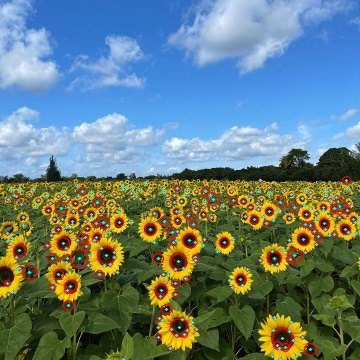

*Figure 1 — Previously generated Q1 detection overlay, retained from the supplied report.*

---
# Question 2 — Custom RANSAC line and circle fitting

**Task:** Fit a line with custom RANSAC and a **unit** normal, remove line consensus, fit a circle to the remainder, show both models and their minimal samples, and explain what happens if the circle is fit first.

The dataset is generated according to the assignment listing: 50 noisy points from a circle with centre $(2,3)$ and radius $10$ ($\sigma_{r}=0.625$); 50 line points with $y=-x+2$ and added vertical Gaussian noise of standard deviation $1$.

The line representation and perpendicular residual are

$$a x+b y=d,\quad a^2+b^2=1,\qquad e_{\text{line}}(p)=|a p_x+b p_y-d|.$$

Two random points define each candidate line; choose the best consensus, then refit by total least squares (SVD). Circle candidates use random non-collinear triples, with radial residual

$$e_{\text{circle}}(p)=\left|\|p-c\|_2-r\right|.$$

Optimize the radial sum-of-squares for the final circle consensus using `scipy.optimize.minimize`.

In [5]:
@dataclass
class LineModel:
    normal: np.ndarray
    d: float
    sample_indices: tuple[int, int]
    inliers: np.ndarray
    sample_normal: np.ndarray
    sample_d: float
    sample_points: np.ndarray


@dataclass
class CircleModel:
    center: np.ndarray
    radius: float
    sample_indices: tuple[int, int, int]
    inliers: np.ndarray
    sample_center: np.ndarray
    sample_radius: float
    sample_points: np.ndarray


def generate_point_set(seed: int = 0, n_total: int = 100):
    """Generate 50 noisy circle points and 50 noisy line points."""

    if n_total % 2:
        raise ValueError("n_total must be even")

    rng = np.random.RandomState(seed)
    half_n = n_total // 2

    # Ground-truth circle: centre (2, 3), radius 10.
    r_gt, x0_gt, y0_gt = 10.0, 2.0, 3.0
    sigma_r = r_gt / 16.0

    t = rng.uniform(0.0, 2.0 * np.pi, half_n)
    noise = sigma_r * rng.randn(half_n)

    xc = x0_gt + (r_gt + noise) * np.cos(t)
    yc = y0_gt + (r_gt + noise) * np.sin(t)

    X_circle = np.column_stack((xc, yc))

    # Ground-truth line: y = -x + 2, with Gaussian noise.
    sigma_line, m_gt, b_gt = 1.0, -1.0, 2.0

    xl = np.linspace(-12.0, 12.0, half_n)
    yl = m_gt * xl + b_gt + sigma_line * rng.randn(half_n)

    X_line = np.column_stack((xl, yl))

    X = np.vstack((X_circle, X_line))

    labels = np.array(
        ["circle"] * half_n + ["line"] * half_n
    )

    # Unit normal representation: ax + by = d.
    normal_gt = np.array([1.0, 1.0]) / np.sqrt(2.0)
    d_gt = 2.0 / np.sqrt(2.0)

    ground_truth = {
        "center": np.array([x0_gt, y0_gt]),
        "radius": r_gt,
        "line_normal": normal_gt,
        "line_d": d_gt,
        "line_m": m_gt,
        "line_b": b_gt,
        "X_circle": X_circle,
        "X_line": X_line,
    }

    return X, labels, ground_truth


def line_from_two_points(p1: np.ndarray, p2: np.ndarray):
    """Return unit normal n and d for n dot p = d."""

    delta = p2 - p1
    length = float(np.linalg.norm(delta))

    if length < 1e-10:
        return None

    tangent = delta / length

    # A perpendicular unit normal.
    normal = np.array(
        [-tangent[1], tangent[0]],
        dtype=float
    )

    normal /= np.linalg.norm(normal)

    d = float(np.dot(normal, p1))

    return normal, d


def line_residuals(
    points: np.ndarray,
    normal: np.ndarray,
    d: float
):
    """Perpendicular distances from points to a line."""

    # Correct because the normal has unit length.
    return np.abs(points @ normal - d)


def tls_line(points: np.ndarray):
    """Refine a line using total least squares."""

    center = points.mean(axis=0)

    _, _, vt = np.linalg.svd(
        points - center,
        full_matrices=False
    )

    direction = vt[0]
    direction /= np.linalg.norm(direction)

    normal = np.array(
        [-direction[1], direction[0]]
    )

    normal /= np.linalg.norm(normal)

    d = float(np.dot(normal, center))

    return normal, d


def ransac_line(
    points: np.ndarray,
    iterations: int = 2500,
    threshold: float = 1.7,
    min_inliers: int = 35,
    seed: int = 123
) -> LineModel:
    """Estimate a line using a custom RANSAC implementation."""

    if len(points) < 2:
        raise ValueError(
            "At least two points are required for line RANSAC"
        )

    rng = np.random.default_rng(seed)

    best_indices = None
    best_key = (-1, float("-inf"))

    for _ in range(iterations):

        # Randomly select two points.
        ids = tuple(
            int(i)
            for i in rng.choice(
                len(points),
                size=2,
                replace=False
            )
        )

        fit = line_from_two_points(
            points[ids[0]],
            points[ids[1]]
        )

        if fit is None:
            continue

        normal, d = fit

        residuals = line_residuals(
            points, normal, d
        )

        inliers = residuals <= threshold
        count = int(inliers.sum())

        # Prefer more inliers, then smaller residual error.
        error = float(
            np.sum(
                np.minimum(
                    residuals[inliers] ** 2,
                    threshold ** 2
                )
            )
        ) if count else float("inf")

        key = (count, -error)

        if key > best_key:
            best_key = key
            best_indices = ids
            best_inliers = inliers.copy()

            sample_normal = normal.copy()
            sample_d = d

    if (
        best_indices is None
        or int(best_inliers.sum()) < min_inliers
    ):
        count = (
            0 if best_indices is None
            else int(best_inliers.sum())
        )

        raise RuntimeError(
            f"Line RANSAC failed: {count} inliers; "
            f"minimum required is {min_inliers}."
        )

    # Refine the winning model using all its consensus points.
    normal, d = tls_line(points[best_inliers])

    final_inliers = (
        line_residuals(points, normal, d) <= threshold
    )

    return LineModel(
        normal=normal,
        d=d,
        sample_indices=best_indices,
        inliers=final_inliers,
        sample_normal=sample_normal,
        sample_d=sample_d,
        sample_points=points[list(best_indices)].copy()
    )

In [6]:
def circle_from_three_points(points: np.ndarray):
    """Calculate circle centre and radius from three points."""

    p1, p2, p3 = points

    matrix = 2.0 * np.array(
        [p2 - p1, p3 - p1],
        dtype=float
    )

    rhs = np.array([
        np.dot(p2, p2) - np.dot(p1, p1),
        np.dot(p3, p3) - np.dot(p1, p1)
    ])

    # Collinear or nearly collinear sample points.
    if abs(float(np.linalg.det(matrix))) < 1e-8:
        return None

    center = np.linalg.solve(matrix, rhs)

    radius = float(
        np.linalg.norm(p1 - center)
    )

    if not np.isfinite(radius) or radius <= 0:
        return None

    return center, radius


def circle_residuals(
    points: np.ndarray,
    center: np.ndarray,
    radius: float
):
    """Absolute radial errors for a proposed circle."""

    distances = np.linalg.norm(
        points - center[None, :],
        axis=1
    )

    return np.abs(distances - radius)


def optimize_circle(
    points: np.ndarray,
    initial_center: np.ndarray,
    initial_radius: float
):
    """Minimize the sum of squared radial residuals."""

    def objective(params):

        cx, cy, radius = params

        if radius <= 0:
            return 1e12 + 1e8 * abs(radius)

        center = np.array([cx, cy])

        residuals = (
            np.linalg.norm(
                points - center[None, :],
                axis=1
            ) - radius
        )

        return float(np.dot(residuals, residuals))

    start = np.array([
        initial_center[0],
        initial_center[1],
        max(1e-3, initial_radius)
    ], dtype=float)

    result = minimize(
        objective,
        start,
        method="Nelder-Mead",
        options={
            "maxiter": 5000,
            "xatol": 1e-8,
            "fatol": 1e-8
        }
    )

    if not result.success and not np.isfinite(result.fun):
        raise RuntimeError(
            f"Circle optimization failed: {result.message}"
        )

    cx, cy, radius = result.x

    return np.array([cx, cy]), float(abs(radius))


def ransac_circle(
    points: np.ndarray,
    iterations: int = 4500,
    threshold: float = 1.25,
    min_inliers: int = 32,
    seed: int = 456
) -> CircleModel:
    """Estimate a circle using a custom RANSAC implementation."""

    if len(points) < 3:
        raise ValueError(
            "At least three points are required for circle RANSAC"
        )

    rng = np.random.default_rng(seed)

    best_indices = None
    best_key = (-1, float("-inf"))

    for _ in range(iterations):

        # Randomly choose three points.
        ids = tuple(
            int(i)
            for i in rng.choice(
                len(points),
                size=3,
                replace=False
            )
        )

        fit = circle_from_three_points(
            points[list(ids)]
        )

        if fit is None:
            continue

        center, radius = fit

        # Reject degenerate or excessively large circles.
        if radius > 100.0 or radius < 1.0:
            continue

        residuals = circle_residuals(
            points, center, radius
        )

        inliers = residuals <= threshold
        count = int(inliers.sum())

        error = float(
            np.sum(
                np.minimum(
                    residuals[inliers] ** 2,
                    threshold ** 2
                )
            )
        ) if count else float("inf")

        key = (count, -error)

        if key > best_key:
            best_key = key
            best_indices = ids
            best_inliers = inliers.copy()

            sample_center = center.copy()
            sample_radius = radius

    if (
        best_indices is None
        or int(best_inliers.sum()) < min_inliers
    ):
        count = (
            0 if best_indices is None
            else int(best_inliers.sum())
        )

        raise RuntimeError(
            f"Circle RANSAC failed: {count} inliers; "
            f"minimum required is {min_inliers}."
        )

    # Optimize using the consensus of the best sample.
    center, radius = optimize_circle(
        points[best_inliers],
        sample_center,
        sample_radius
    )

    final_inliers = (
        circle_residuals(
            points, center, radius
        ) <= threshold
    )

    # Refine once more using the updated consensus.
    if int(final_inliers.sum()) >= 3:

        center, radius = optimize_circle(
            points[final_inliers],
            center,
            radius
        )

        final_inliers = (
            circle_residuals(
                points, center, radius
            ) <= threshold
        )

    return CircleModel(
        center=center,
        radius=radius,
        sample_indices=best_indices,
        inliers=final_inliers,
        sample_center=sample_center,
        sample_radius=sample_radius,
        sample_points=points[list(best_indices)].copy()
    )


def line_y(normal, d, x):

    nx, ny = normal

    if abs(ny) < 1e-8:
        return np.full_like(x, np.nan, dtype=float)

    return (d - nx * x) / ny

## Parameters used for the reported experiment

| Model | Iterations | Inlier distance threshold | Minimum consensus | Minimal sample |
|---|---:|---:|---:|---:|
| Line | 2,500 | 1.70 units | 35 points | 2 points |
| Circle | 4,500 | 1.25 units | 32 points | 3 points |

The radial noise σ of the circle is $10/16=0.625$; threshold 1.25 is approximately two of these radial standard deviations. The line receives **vertical noise** σ=1; a line near 45° has lower standard deviation in perpendicular distance (about $1/\sqrt{2}$), while the threshold 1.7 is permissive to maintain consensus.

In [7]:
def run(
    seed: int = 0,
    output_dir: str = "results/q2",
    show: bool = False
):
    out = Path(output_dir)
    out.mkdir(parents=True, exist_ok=True)

    X, labels, gt = generate_point_set(seed=seed)

    # Part (a): detect the line using RANSAC.
    line = ransac_line(
        X,
        threshold=1.7,
        min_inliers=35,
        seed=seed + 1
    )

    # Remove the line consensus before circle fitting.
    remainder_indices = np.flatnonzero(~line.inliers)
    X_remaining = X[remainder_indices]

    # Part (b): fit a circle to the remaining points.
    circle = ransac_circle(
        X_remaining,
        threshold=1.25,
        min_inliers=32,
        seed=seed + 2
    )

    # Map circle inliers back to the original 100-point set.
    circle_global_inliers = np.zeros(
        len(X), dtype=bool
    )

    circle_global_inliers[
        remainder_indices[circle.inliers]
    ] = True

    # Part (d): reverse the order for comparison.
    circle_first = ransac_circle(
        X,
        threshold=1.25,
        min_inliers=32,
        seed=seed + 2
    )

    circle_first_remaining_indices = np.flatnonzero(
        ~circle_first.inliers
    )

    circle_first_line = ransac_line(
        X[circle_first_remaining_indices],
        threshold=1.7,
        min_inliers=35,
        seed=seed + 1
    )

    # -----------------------------------------------------
    # Part (c): plot all points, samples, inliers and models
    # -----------------------------------------------------

    fig, ax = plt.subplots(figsize=(8.5, 7.8))

    # All points.
    ax.scatter(
        X[:, 0], X[:, 1],
        s=20,
        c="#9aa0a6",
        alpha=0.6,
        label="All points",
        zorder=1
    )

    # Inliers for the line.
    ax.scatter(
        X[line.inliers, 0],
        X[line.inliers, 1],
        s=26,
        c="#e0a800",
        label=f"Line inliers ({line.inliers.sum()})",
        zorder=3
    )

    # Inliers for the circle.
    ax.scatter(
        X[circle_global_inliers, 0],
        X[circle_global_inliers, 1],
        s=28,
        c="#10aeb4",
        label=(
            f"Circle inliers "
            f"({circle_global_inliers.sum()})"
        ),
        zorder=4
    )

    # Two points from the best line sample.
    ax.scatter(
        line.sample_points[:, 0],
        line.sample_points[:, 1],
        s=95,
        marker="x",
        c="#d62728",
        linewidths=2.2,
        label="Best line sample (2 points)",
        zorder=7
    )

    # Three points from the best circle sample.
    ax.scatter(
        circle.sample_points[:, 0],
        circle.sample_points[:, 1],
        s=95,
        marker="*",
        c="#7b1fa2",
        edgecolors="white",
        linewidths=0.5,
        label="Best circle sample (3 points)",
        zorder=8
    )

    xgrid = np.linspace(
        X[:, 0].min() - 1,
        X[:, 0].max() + 1,
        350
    )

    # Ground-truth line.
    ax.plot(
        xgrid,
        line_y(
            gt["line_normal"],
            gt["line_d"],
            xgrid
        ),
        "--",
        color="#6c757d",
        lw=1.5,
        label="Ground-truth line"
    )

    # Line from the two points that produced the best sample.
    ax.plot(
        xgrid,
        line_y(
            line.sample_normal,
            line.sample_d,
            xgrid
        ),
        color="#e63946",
        lw=1.1,
        alpha=0.85,
        label="RANSAC sample line"
    )

    # Refined best-fit line.
    ax.plot(
        xgrid,
        line_y(line.normal, line.d, xgrid),
        color="#f08a24",
        lw=2.0,
        label="Best-fit TLS line"
    )

    angles = np.linspace(
        0, 2 * np.pi, 500
    )

    # Ground-truth circle.
    ax.plot(
        gt["center"][0] + gt["radius"] * np.cos(angles),
        gt["center"][1] + gt["radius"] * np.sin(angles),
        color="#7cb342",
        ls="--",
        lw=1.4,
        label="Ground-truth circle"
    )

    # Circle estimated only from the winning three-point sample.
    ax.plot(
        circle.sample_center[0]
        + circle.sample_radius * np.cos(angles),
        circle.sample_center[1]
        + circle.sample_radius * np.sin(angles),
        color="#7b1fa2",
        lw=1.1,
        alpha=0.8,
        label="Circle from best sample"
    )

    # Optimized best-fit circle.
    ax.plot(
        circle.center[0] + circle.radius * np.cos(angles),
        circle.center[1] + circle.radius * np.sin(angles),
        color="#006d77",
        lw=2.0,
        label="Optimized best-fit circle"
    )

    ax.set(
        xlabel="x",
        ylabel="y",
        title="RANSAC line-first fitting: line and circle"
    )

    ax.grid(True, alpha=0.25)
    ax.axis("equal")

    ax.legend(
        fontsize=7.4,
        loc="upper right",
        framealpha=0.92
    )

    fig.tight_layout()

    plot_path = out / "ransac_line_circle.png"

    fig.savefig(
        plot_path,
        dpi=180,
        bbox_inches="tight"
    )

    if show:
        plt.show()

    plt.close(fig)

    # -----------------------------------------------------
    # 6. Save numerical results for the report
    # -----------------------------------------------------

    fitted_slope = (
        -line.normal[0] / line.normal[1]
        if abs(line.normal[1]) > 1e-9
        else float("inf")
    )

    fitted_intercept = (
        line.d / line.normal[1]
        if abs(line.normal[1]) > 1e-9
        else float("nan")
    )

    metrics_path = out / "metrics.txt"

    with metrics_path.open(
        "w", encoding="utf-8"
    ) as f:

        f.write(f"Random seed: {seed}\n")

        f.write(
            f"Line inliers: {int(line.inliers.sum())}/100; "
            "threshold=1.7; min consensus=35\n"
        )

        f.write(
            f"Line unit normal: "
            f"[{line.normal[0]:.6f}, "
            f"{line.normal[1]:.6f}], "
            f"norm={np.linalg.norm(line.normal):.6f}\n"
        )

        f.write(
            f"Line d: {line.d:.6f}; "
            f"approximate y=m*x+b: "
            f"m={fitted_slope:.6f}, "
            f"b={fitted_intercept:.6f}\n"
        )

        f.write(
            f"Line sample points: "
            f"{line.sample_points.tolist()}\n"
        )

        f.write(
            f"Circle inliers after line removal: "
            f"{int(circle_global_inliers.sum())}; "
            "threshold=1.25; min consensus=32\n"
        )

        f.write(
            f"Circle center: "
            f"({circle.center[0]:.6f}, "
            f"{circle.center[1]:.6f}); "
            f"radius={circle.radius:.6f}\n"
        )

        f.write(
            f"Circle sample points: "
            f"{circle.sample_points.tolist()}\n"
        )

        # Check the true composition of the consensuses.
        line_true = int(
            np.sum(
                line.inliers & (labels == "line")
            )
        )

        line_circle = int(
            np.sum(
                line.inliers & (labels == "circle")
            )
        )

        circle_true = int(
            np.sum(
                circle_global_inliers
                & (labels == "circle")
            )
        )

        circle_line = int(
            np.sum(
                circle_global_inliers
                & (labels == "line")
            )
        )

        f.write(
            f"Line consensus composition: "
            f"{line_true} true-line + "
            f"{line_circle} true-circle points\n"
        )

        f.write(
            f"Circle consensus composition: "
            f"{circle_true} true-circle + "
            f"{circle_line} true-line points\n"
        )

        # Results when circle fitting is attempted first.
        cf_circle_true = int(
            np.sum(
                circle_first.inliers
                & (labels == "circle")
            )
        )

        cf_circle_line = int(
            np.sum(
                circle_first.inliers
                & (labels == "line")
            )
        )

        remaining_labels = labels[
            circle_first_remaining_indices
        ]

        cf_line_true = int(
            np.sum(
                circle_first_line.inliers
                & (remaining_labels == "line")
            )
        )

        cf_line_circle = int(
            np.sum(
                circle_first_line.inliers
                & (remaining_labels == "circle")
            )
        )

        f.write(
            f"Circle-first: "
            f"{int(circle_first.inliers.sum())} "
            f"circle consensus = "
            f"{cf_circle_true} true-circle + "
            f"{cf_circle_line} true-line points\n"
        )

        f.write(
            f"Circle-first remainder: "
            f"{len(circle_first_remaining_indices)} points; "
            f"line fit inliers="
            f"{int(circle_first_line.inliers.sum())} "
            f"({cf_line_true} true-line + "
            f"{cf_line_circle} true-circle)\n"
        )

        f.write(
            "Ground truth line: y=-x+2; "
            "circle center=(2,3), radius=10\n"
        )

    print(metrics_path.read_text())

    print(f"Plot saved: {plot_path.resolve()}")

    return {
        "X": X,
        "line": line,
        "circle": circle,
        "circle_global_inliers": circle_global_inliers,
        "ground_truth": gt,
        "circle_first": circle_first,
        "circle_first_line": circle_first_line,
    }

In [8]:
# Rerunnable: no external photographs required.
q2_result = run(seed=0, output_dir=str(RESULTS_ROOT / 'q2'), show=False)
print('Q2 completed. Plot and metrics are under results/q2.')

Random seed: 0
Line inliers: 56/100; threshold=1.7; min consensus=35
Line unit normal: [0.715649, 0.698460], norm=1.000000
Line d: 1.561775; approximate y=m*x+b: m=-1.024609, b=2.236025
Line sample points: [[-12.0, 14.20827497807686], [2.6938775510204085, -0.3956393768143525]]
Circle inliers after line removal: 42; threshold=1.25; min consensus=32
Circle center: (1.817367, 3.089484); radius=9.888575
Circle sample points: [[11.05786244234232, 7.334549756511372], [-5.4462458629496355, -3.727311615406169], [-7.81618802610293, 5.423339906701143]]
Line consensus composition: 50 true-line + 6 true-circle points
Circle consensus composition: 42 true-circle + 0 true-line points
Circle-first: 57 circle consensus = 48 true-circle + 9 true-line points
Circle-first remainder: 43 points; line fit inliers=41 (41 true-line + 0 true-circle)
Ground truth line: y=-x+2; circle center=(2,3), radius=10

Plot saved: /mnt/data/results/q2/ransac_line_circle.png
Q2 completed. Plot and metrics are under results

## Results and comparison

| Quantity | True parameter | Recorded fitted estimate |
|---|---|---|
| Line slope | −1.000000 | −1.024609 |
| Line intercept | 2.000000 | 2.236025 |
| Unit normal | (0.707107, 0.707107) | (0.715649, 0.698460) |
| Distance parameter d | 1.414214 | 1.561775 |
| Circle centre | (2, 3) | (1.817367, 3.089484) |
| Circle radius | 10.000000 | 9.888575 |

The recorded **line-first** consensus contains 56 points (50 true line + 6 true circle). Fitting the circle to the 44 remaining points returns 42 circle inliers, all originating from the true circle; the other 2 are not classified as circle inliers. The fitted centre error is approximately **0.2034**, and the radius error is approximately **0.1114**.

### Part (d): What if the circle is fitted first?

The recorded circle-first experiment identifies 57 points for the circle (48 true circle + 9 line points). After removing them, line RANSAC identifies 41 true-line inliers. This demonstrates a practical limitation of sequential fitting: when models overlap or their error thresholds admit some of the other class, the model fitted first can absorb points that should belong to the second. *Order affects estimated consensus composition even when the true models are unchanged.*

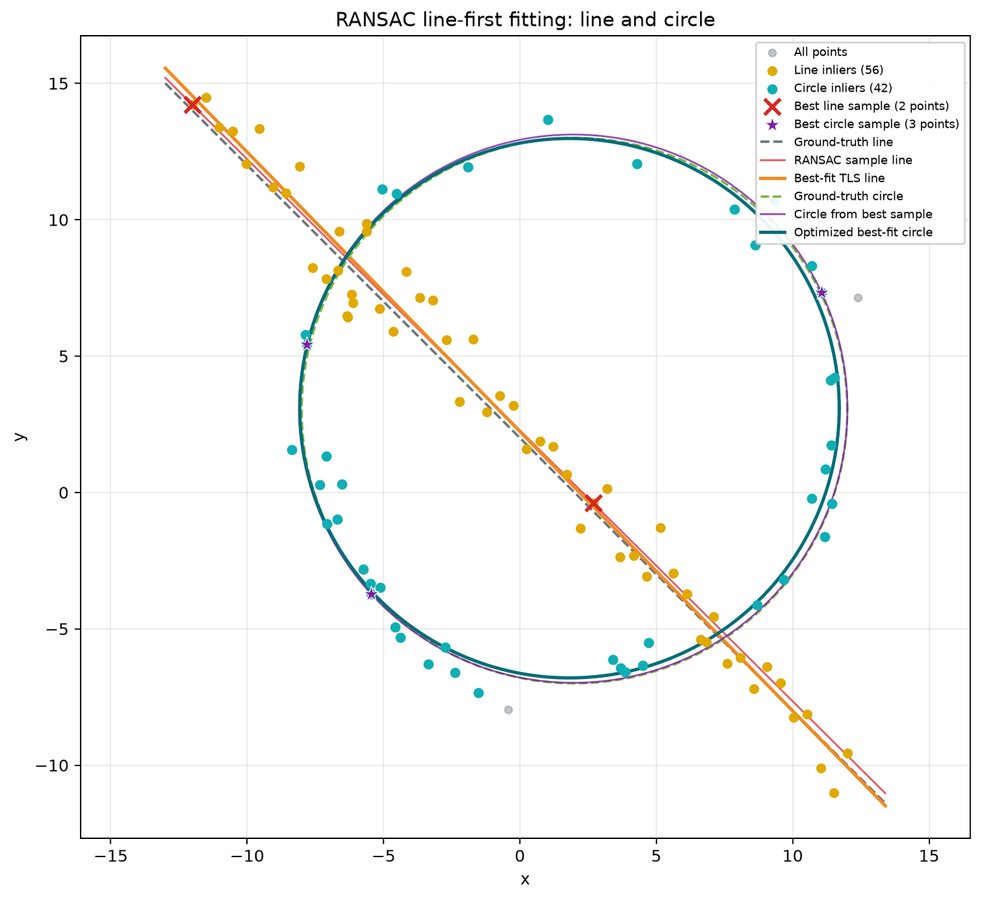

*Figure 2 — Previously generated Q2 visualization, including samples, inliers, true models and fitted models.*

---
# Question 3 — Homography and perspective overlay

**Task:** Choose two background/overlay image pairs, select corresponding corners on a planar target, compute a homography, warp, and blend.

A planar projective transform is defined by homogeneous image points:

$$\lambda\begin{bmatrix}x'\\y'\\1\end{bmatrix}
=H\begin{bmatrix}x\\y\\1\end{bmatrix}, \quad H\in\mathbb{R}^{3\times3}.$$

Four non-collinear corresponding corners allow `cv2.getPerspectiveTransform` to estimate $H$. `cv2.warpPerspective` maps the overlay to the background coordinates. Warp a binary mask separately to avoid black borders contaminating the background. The blend is $I=(\alpha\,I_{\rm overlay}+(1-\alpha)I_{\rm background})$ **inside** the projected target polygon only.

**Existing report examples:** Union Jack on the architecture façade, and a sunflower-image poster on another part of the *same* architecture image. These are two overlay combinations but **not two independent background scenes**. Consider adding an entirely different photographic background to better satisfy the task's “of your own choice” instruction.

In [9]:
def composite(
    background: np.ndarray,
    overlay: np.ndarray,
    dst_points,
    alpha: float = 1.0,
):
    """Warp an overlay rectangle to four destination points and blend it in."""

    if background is None or overlay is None:
        raise ValueError(
            "Background and overlay images must both be readable"
        )

    if not 0.0 <= alpha <= 1.0:
        raise ValueError("alpha must be between 0 and 1")

    h, w = background.shape[:2]
    oh, ow = overlay.shape[:2]

    # Four source-image corners in this order:
    # top-left, top-right, bottom-right, bottom-left.
    src = np.array(
        [
            [0, 0],
            [ow - 1, 0],
            [ow - 1, oh - 1],
            [0, oh - 1],
        ],
        dtype=np.float32,
    )

    # Corresponding four corners on the background plane.
    dst = np.asarray(
        dst_points, dtype=np.float32
    ).reshape(4, 2)

    # Estimate the projective transformation.
    H = cv2.getPerspectiveTransform(src, dst)

    # Warp the overlay into the background image coordinates.
    warped = cv2.warpPerspective(
        overlay,
        H,
        (w, h),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(0, 0, 0),
    )

    # Warp a mask so pixels outside the overlay are not blended.
    source_mask = np.full(
        (oh, ow), 255, dtype=np.uint8
    )

    warped_mask = cv2.warpPerspective(
        source_mask,
        H,
        (w, h),
        flags=cv2.INTER_NEAREST,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0,
    )

    mask = warped_mask > 0

    # Blend only inside the projected quadrilateral.
    out = background.copy()

    out[mask] = np.clip(
        alpha * warped[mask]
        + (1.0 - alpha) * background[mask],
        0,
        255,
    ).astype(np.uint8)

    # Draw a thin red outline for visualising the target plane.
    cv2.polylines(
        out,
        [dst.astype(np.int32)],
        isClosed=True,
        color=(0, 0, 255),
        thickness=1,
        lineType=cv2.LINE_AA,
    )

    return out, H

## Four-point mappings used in the report

Corner order is top-left → top-right → bottom-right → bottom-left.

| Scene | Background | Overlay | Destination points (pixels) | α |
|---|---|---|---|---:|
| 1 | `wadham.jpg` | `flag.png` | (220,250), (480,277), (474,410), (215,394) | 0.97 |
| 2 | `wadham.jpg` | `the_berry_farms_sunflower_field.jpeg` | (72,295), (185,303), (181,382), (69,374) | 0.97 |

The corner order matters: mixed ordering can twist, flip or invert the projected image. Homography assumes one plane and does not model protrusions or depth changes.

In [10]:
# Rerun Q3 when background and overlays have been supplied.
examples = [
    dict(name='flag', background=IMAGE_ROOT/'wadham.jpg',
         overlay=IMAGE_ROOT/'flag.png',
         points=[(220,250),(480,277),(474,410),(215,394)],alpha=0.97),
    dict(name='sunflower_poster', background=IMAGE_ROOT/'wadham.jpg',
         overlay=IMAGE_ROOT/'the_berry_farms_sunflower_field.jpeg',
         points=[(72,295),(185,303),(181,382),(69,374)],alpha=0.97),
]
q3_dir=RESULTS_ROOT/'q3'; q3_dir.mkdir(exist_ok=True)
for example in examples:
    if not example['background'].exists() or not example['overlay'].exists():
        print('Not rerun; missing originals for Q3 scene:',example['name'])
        continue
    bg=cv2.imread(str(example['background']))
    ov=cv2.imread(str(example['overlay']))
    out,H=composite(bg,ov,example['points'],example['alpha'])
    out_path=q3_dir/(example['name']+'.jpg')
    cv2.imwrite(str(out_path),out)
    np.savetxt(q3_dir/(example['name']+'_H.txt'),H,fmt='%.8f')
    print('Saved:',out_path,'\nHomography:\n',H)
    plt.figure(figsize=(10,5));plt.imshow(cv2.cvtColor(out,cv2.COLOR_BGR2RGB));plt.axis('off');plt.show()

Not rerun; missing originals for Q3 scene: flag
Not rerun; missing originals for Q3 scene: sunflower_poster


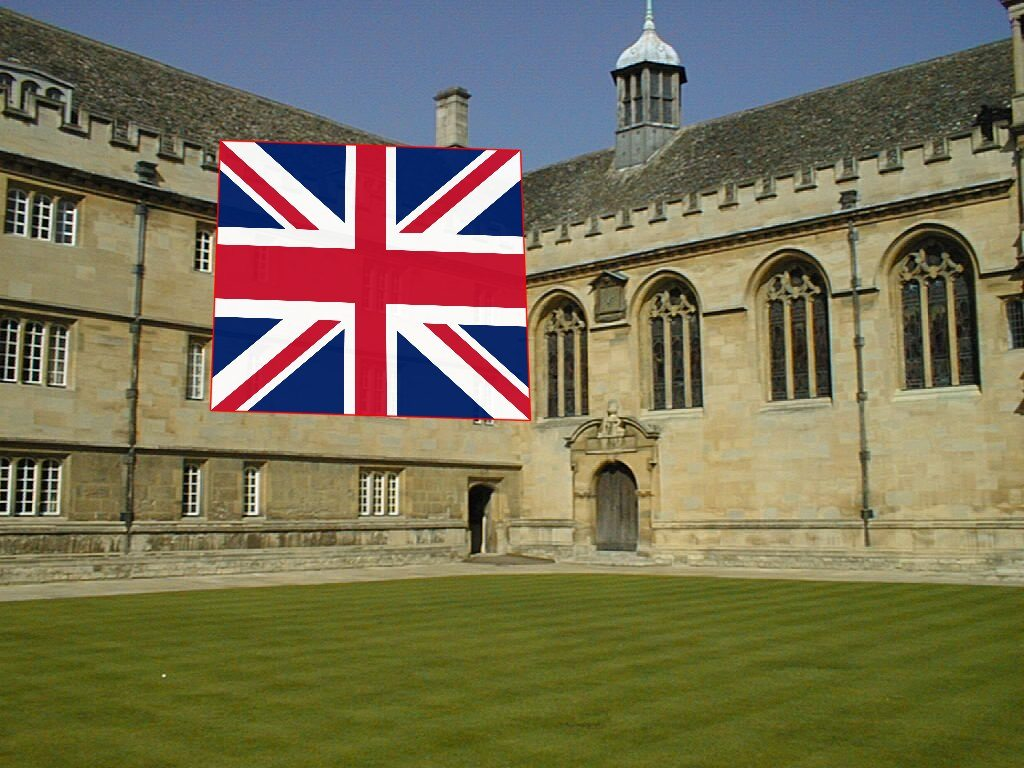

*Figure 3a — Previously generated overlay of the Union Jack on the Wadham College façade.*

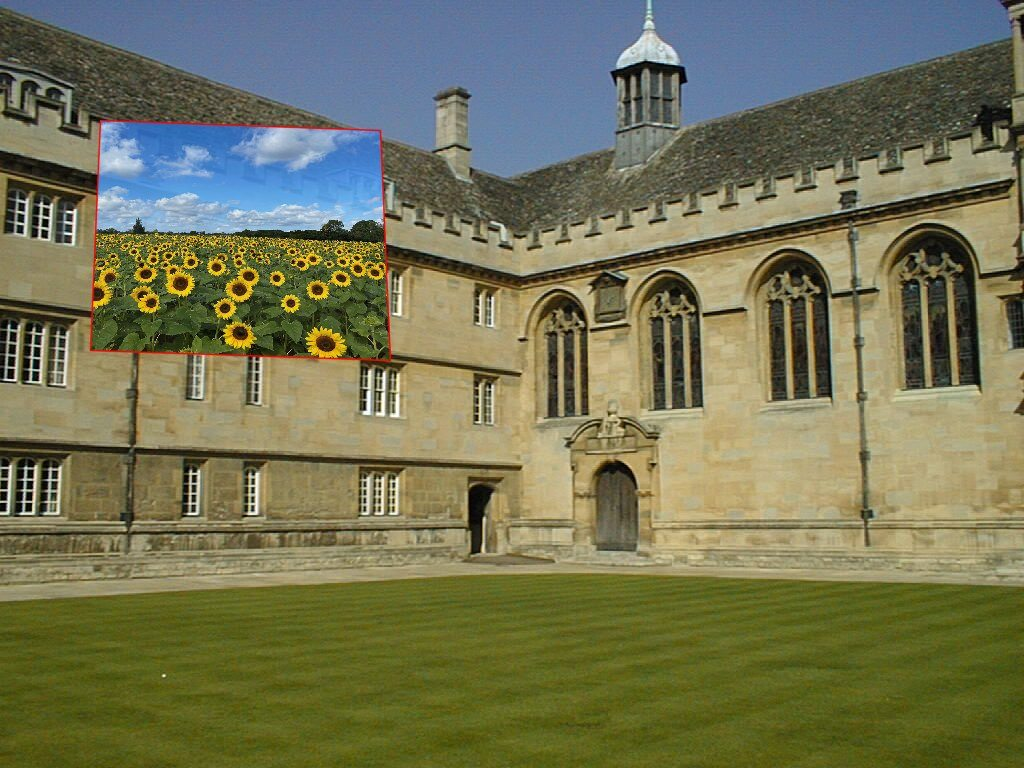

*Figure 3b — Previously generated sunflower-poster overlay on the same architectural background.*

---
# Question 4 — SIFT PCB alignment and image differences

**Task:** For each PCB image, detect SIFT features, match with `cv2.BFMatcher`, estimate a robust homography using RANSAC, warp onto `AECC1.jpg`, show matched keypoints, and calculate/show the difference image. Explain why parts such as connectors, capacitors and the reset switch produce high differences.

**Algorithm used**

1. Compute SIFT descriptors in template and candidate image.
2. Match using BFMatcher and Euclidean descriptor distance. Apply Lowe's ratio test at **0.75**.
3. Estimate the homography from PCB coordinates to template coordinates with RANSAC, reprojection tolerance **5 pixels**.
4. Warp each candidate and a binary coverage mask to the reference geometry.
5. Calculate the per-channel absolute colour differences using `cv2.absdiff`; then convert that colour difference to grayscale for summary metrics. **This is not identical to** `abs(gray(reference) - gray(aligned))`.
6. Exclude pixels outside warped coverage, and save matching visualizations, alignment, absolute-difference greyscale output, heatmap, and metrics.

In [11]:
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}

def align_and_compare(
    template_path: Path,
    pcb_path: Path,
    output_dir: Path,
    ratio: float = 0.75,
    ransac_threshold: float = 5.0,
):
    """Align one PCB image to the template and compute differences."""

    template = cv2.imread(
        str(template_path), cv2.IMREAD_COLOR
    )

    pcb = cv2.imread(
        str(pcb_path), cv2.IMREAD_COLOR
    )

    if template is None:
        raise FileNotFoundError(
            f"Cannot read template: {template_path}"
        )

    if pcb is None:
        raise FileNotFoundError(
            f"Cannot read PCB image: {pcb_path}"
        )

    # -----------------------------------------------------
    # Step 1: Detect SIFT features in both images.
    # -----------------------------------------------------

    sift = cv2.SIFT_create()

    template_gray = cv2.cvtColor(
        template, cv2.COLOR_BGR2GRAY
    )

    pcb_gray = cv2.cvtColor(
        pcb, cv2.COLOR_BGR2GRAY
    )

    key_template, desc_template = sift.detectAndCompute(
        template_gray, None
    )

    key_pcb, desc_pcb = sift.detectAndCompute(
        pcb_gray, None
    )

    if (
        desc_template is None
        or desc_pcb is None
        or len(key_template) < 4
        or len(key_pcb) < 4
    ):
        raise RuntimeError(
            f"Not enough SIFT features in "
            f"{pcb_path.name} or template"
        )

    # -----------------------------------------------------
    # Step 2: Match SIFT descriptors using BFMatcher.
    # SIFT descriptors are floating-point vectors;
    # use the L2 distance metric.
    # -----------------------------------------------------

    matcher = cv2.BFMatcher(
        cv2.NORM_L2,
        crossCheck=False,
    )

    pairs = matcher.knnMatch(
        desc_pcb,
        desc_template,
        k=2,
    )

    # Lowe's ratio test removes ambiguous feature matches.
    good = [
        m for m, n in pairs
        if m.distance < ratio * n.distance
    ]

    if len(good) < 4:
        raise RuntimeError(
            f"Only {len(good)} ratio-test matches "
            f"for {pcb_path.name}; need at least 4"
        )

    # Source points belong to the PCB.
    src_pts = np.float32([
        key_pcb[m.queryIdx].pt
        for m in good
    ]).reshape(-1, 1, 2)

    # Destination points belong to the template.
    dst_pts = np.float32([
        key_template[m.trainIdx].pt
        for m in good
    ]).reshape(-1, 1, 2)

    # -----------------------------------------------------
    # Step 3: Estimate the homography with RANSAC.
    # -----------------------------------------------------

    H, inlier_mask = cv2.findHomography(
        src_pts,
        dst_pts,
        cv2.RANSAC,
        ransac_threshold,
    )

    if H is None or inlier_mask is None:
        raise RuntimeError(
            f"RANSAC homography estimation failed "
            f"for {pcb_path.name}"
        )

    inliers = inlier_mask.ravel().astype(bool)

    inlier_matches = [
        m for m, keep in zip(good, inliers)
        if keep
    ]

    # -----------------------------------------------------
    # Step 4: Warp the PCB into template coordinates.
    # -----------------------------------------------------

    th, tw = template.shape[:2]

    aligned = cv2.warpPerspective(
        pcb,
        H,
        (tw, th),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(0, 0, 0),
    )

    # Warp a validity mask as well. This identifies which
    # output pixels actually come from the input PCB.
    source_valid = np.full(
        pcb.shape[:2],
        255,
        dtype=np.uint8,
    )

    warped_valid = cv2.warpPerspective(
        source_valid,
        H,
        (tw, th),
        flags=cv2.INTER_NEAREST,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0,
    )

    valid = warped_valid > 0

    # -----------------------------------------------------
    # Step 5: Compute the absolute difference image.
    # -----------------------------------------------------

    diff = cv2.absdiff(
        template,
        aligned,
    )

    diff_gray = cv2.cvtColor(
        diff,
        cv2.COLOR_BGR2GRAY,
    )

    # Exclude uncovered pixels from the difference analysis.
    diff_gray[~valid] = 0

    # A colour heatmap makes larger differences easier to see.
    heat = cv2.applyColorMap(
        diff_gray,
        cv2.COLORMAP_JET,
    )

    heat[~valid] = (0, 0, 0)

    # Blend the template and aligned PCB for visual comparison.
    overlay = cv2.addWeighted(
        template, 0.55,
        aligned, 0.45,
        0,
    )

    # Show the original template in uncovered regions.
    overlay[~valid] = template[~valid]

    # -----------------------------------------------------
    # Step 6: Save all outputs.
    # -----------------------------------------------------

    output_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    stem = pcb_path.stem

    # Limit the displayed match lines for readability.
    # The metrics still use every ratio-test match/inlier.
    preview_matches = sorted(
        inlier_matches,
        key=lambda m: m.distance,
    )[:75]

    matches_vis = cv2.drawMatches(
        pcb,
        key_pcb,
        template,
        key_template,
        preview_matches,
        None,
        matchColor=(30, 210, 70),
        singlePointColor=(240, 180, 30),
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS,
    )

    outputs = {
        "matches": output_dir / f"{stem}_matches.jpg",
        "aligned": output_dir / f"{stem}_aligned.jpg",
        "difference_gray": (
            output_dir / f"{stem}_difference_gray.png"
        ),
        "difference_heatmap": (
            output_dir / f"{stem}_difference_heatmap.png"
        ),
        "overlay": (
            output_dir / f"{stem}_overlay_comparison.jpg"
        ),
        "homography": (
            output_dir / f"{stem}_homography.txt"
        ),
    }

    if not cv2.imwrite(
        str(outputs["matches"]), matches_vis
    ):
        raise OSError(
            f"Could not save {outputs['matches']}"
        )

    if not cv2.imwrite(
        str(outputs["aligned"]), aligned
    ):
        raise OSError(
            f"Could not save {outputs['aligned']}"
        )

    if not cv2.imwrite(
        str(outputs["difference_gray"]), diff_gray
    ):
        raise OSError(
            f"Could not save {outputs['difference_gray']}"
        )

    if not cv2.imwrite(
        str(outputs["difference_heatmap"]), heat
    ):
        raise OSError(
            f"Could not save {outputs['difference_heatmap']}"
        )

    if not cv2.imwrite(
        str(outputs["overlay"]), overlay
    ):
        raise OSError(
            f"Could not save {outputs['overlay']}"
        )

    np.savetxt(
        outputs["homography"],
        H,
        fmt="%.8f",
    )

    # -----------------------------------------------------
    # Step 7: Quantify differences over valid pixels only.
    # -----------------------------------------------------

    valid_count = int(valid.sum())

    if valid_count:
        mean_diff = float(
            diff_gray[valid].mean()
        )

        median_diff = float(
            np.median(diff_gray[valid])
        )

        p95_diff = float(
            np.percentile(
                diff_gray[valid],
                95,
            )
        )
    else:
        mean_diff = float("nan")
        median_diff = float("nan")
        p95_diff = float("nan")

    metrics = {
        "pcb_image": pcb_path.name,
        "template": template_path.name,
        "template_keypoints": len(key_template),
        "pcb_keypoints": len(key_pcb),
        "ratio_test_matches": len(good),
        "ransac_inliers": int(inliers.sum()),
        "inlier_ratio": (
            float(inliers.mean())
            if len(inliers)
            else 0.0
        ),
        "valid_overlap_pixels": valid_count,
        "mean_abs_gray_difference": mean_diff,
        "median_abs_gray_difference": median_diff,
        "p95_abs_gray_difference": p95_diff,
    }

    print(metrics)

    return metrics

In [12]:
# Rerun Q4 when the original PCB photographs have been placed in images/pcb/.
pcb_dir = IMAGE_ROOT/'pcb'
template_path = pcb_dir/'AECC1.jpg'
q4_out = RESULTS_ROOT/'q4'
if not template_path.exists():
    print('PCB reference missing — Q4 was not rerun. See recorded metrics and heatmaps below.')
else:
    test_files = sorted(p for p in pcb_dir.iterdir() if p.is_file()
                        and p.suffix.lower() in IMAGE_EXTS
                        and p.resolve()!=template_path.resolve())
    if not test_files:
        print('No test PCB images found next to the template.')
    else:
        summary=[]
        for p in test_files:
            try:
                summary.append(align_and_compare(template_path,p,q4_out,ratio=0.75,ransac_threshold=5.0))
            except Exception as error:
                summary.append({'pcb_image':p.name,'error':str(error)})
                print('Error for',p.name, ':', error)
        report=pd.DataFrame(summary)
        display(report)
        report.to_csv(q4_out/'summary.csv',index=False)

PCB reference missing — Q4 was not rerun. See recorded metrics and heatmaps below.


## Q4 recorded metrics

*The numerical values below were copied from the supplied Assignment 2 report, not recomputed in this notebook because the PCB source images are unavailable.*

| Candidate PCB | Ratio-test matches | RANSAC inliers | Mean weighted absolute colour difference | 95th percentile |
|---|---:|---:|---:|---:|
| AAAA1 | 51 | 18 | 28.8 | 107 |
| ADAD1 | 369 | 194 | 31.2 | 92 |
| AECC2 | 4,322 | 3,847 | 3.5 | 9 |
| AECC3 | 5,629 | 5,006 | 3.2 | 8 |
| AECC4 | 3,830 | 3,402 | 4.0 | 10 |

**Interpretation:** AECC2–AECC4 align relatively well and have low difference statistics compared with AAAA1 and ADAD1. AAAA1 has a particularly low inlier ratio (18/51 ≈ 35.3%), so its difference map should be interpreted with care: poor registration can look like an object difference. Larger differences near the USB Type-B connector, capacitors and reset button may arise from genuine component differences, local height/parallax, view or illumination changes, occlusion, interpolation, or small residual misalignment. A homography corrects global planar perspective—not 3D component structure—and a heatmap alone does not prove a manufacturing defect.

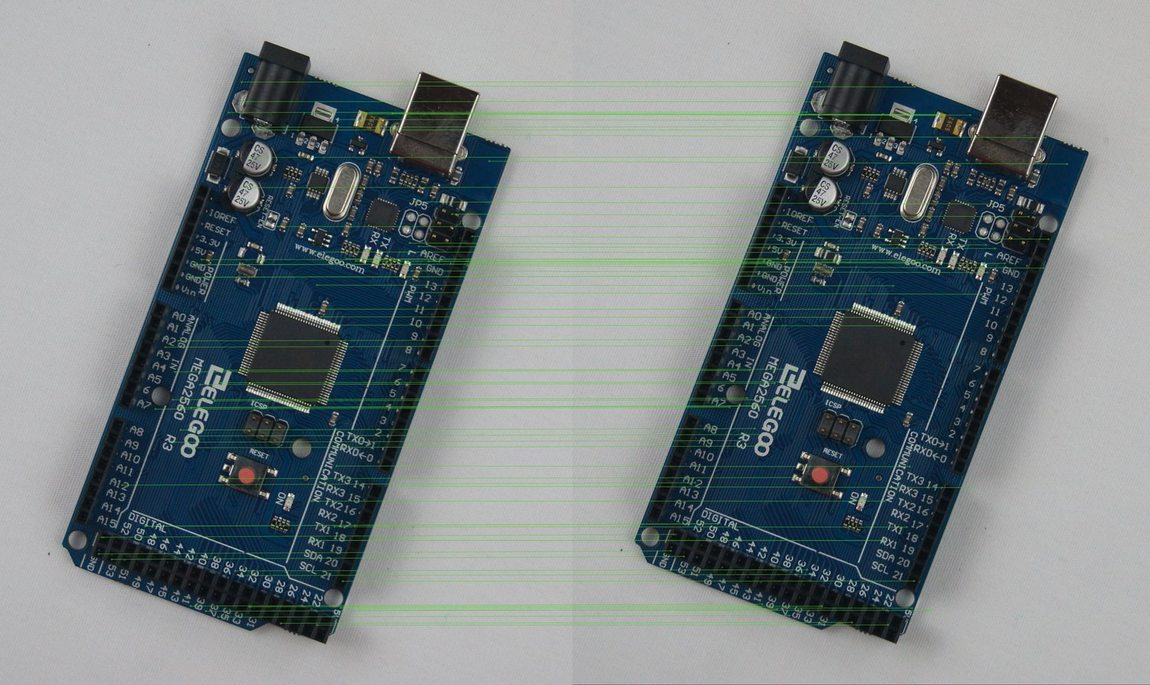

*Figure 4a — Previously generated SIFT inlier matches: AECC2 aligned to reference AECC1.*

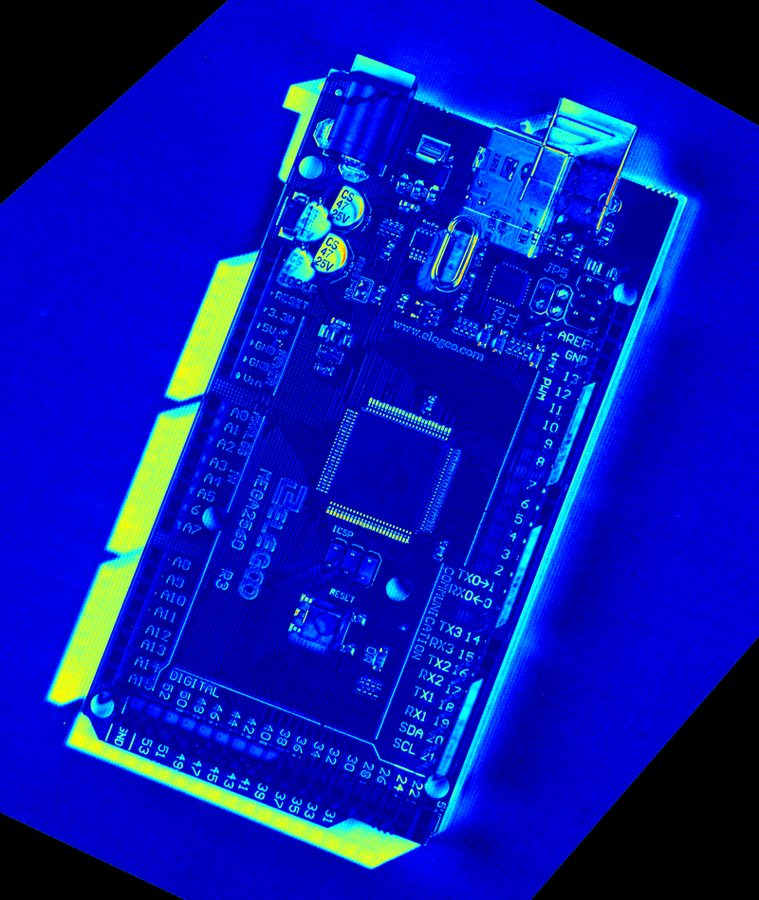

*Figure 4 — Saved difference heatmap for AAAA1 against reference AECC1 (recorded output).*

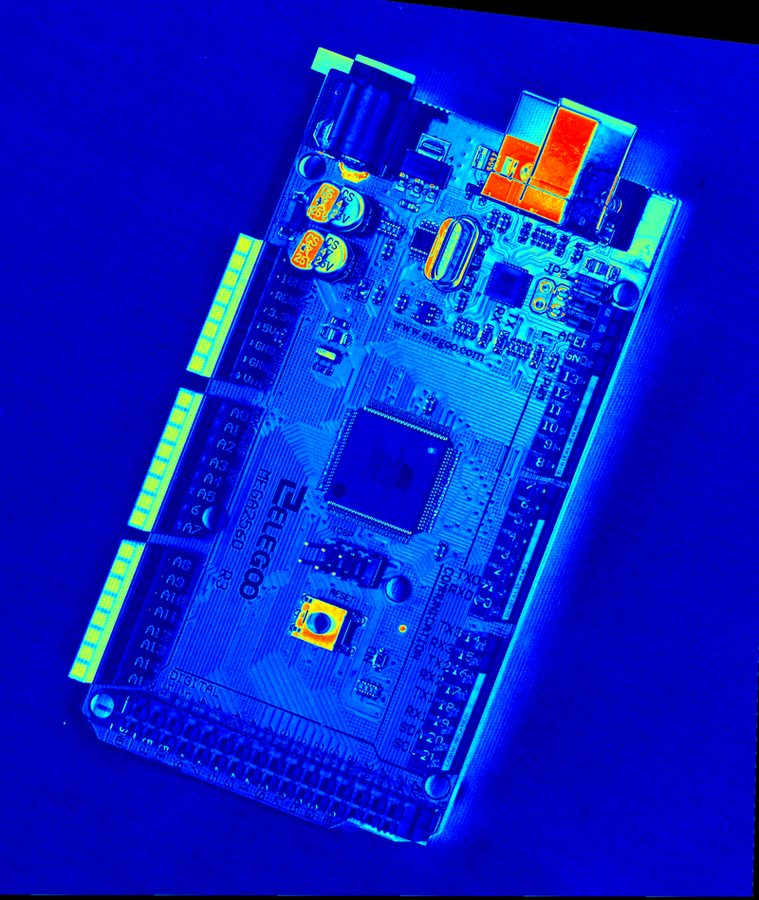

*Figure 4 — Saved difference heatmap for ADAD1 against reference AECC1 (recorded output).*

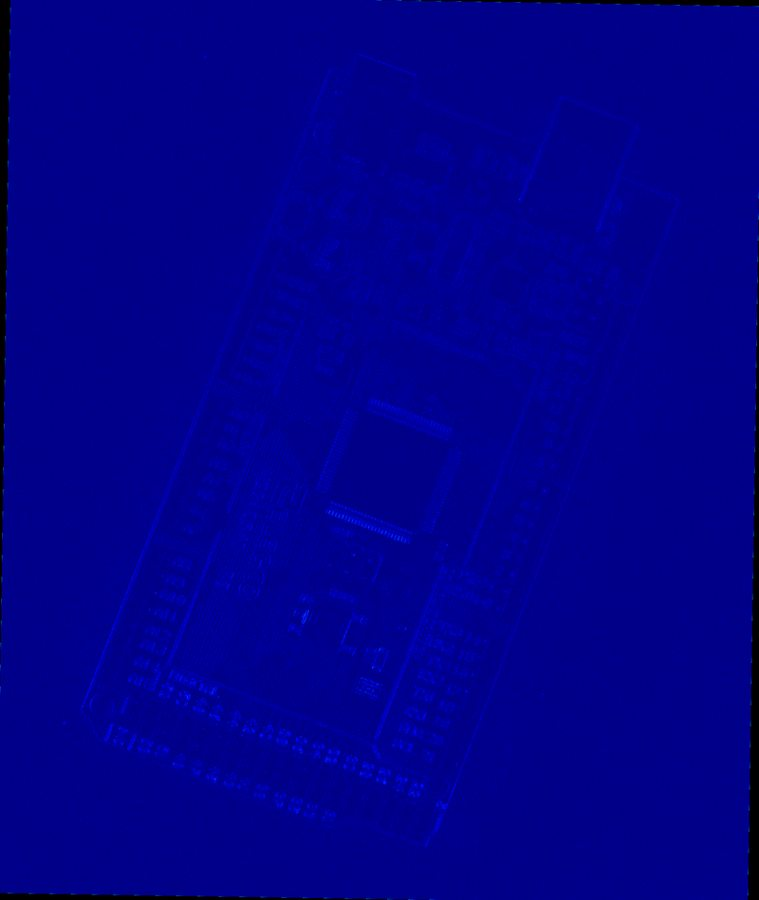

*Figure 4 — Saved difference heatmap for AECC2 against reference AECC1 (recorded output).*

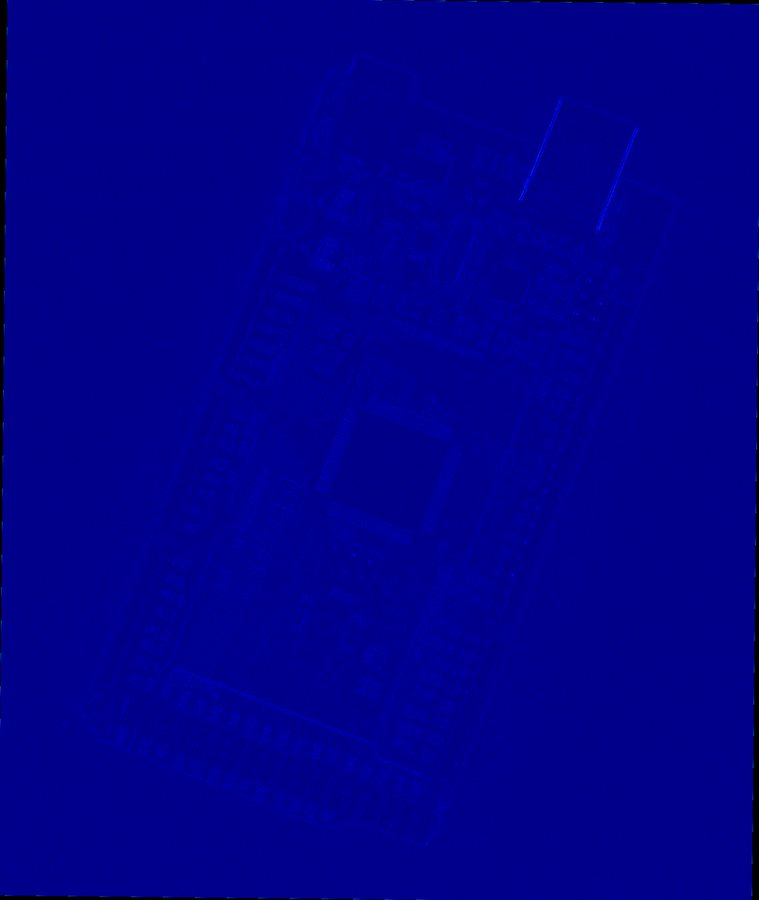

*Figure 4 — Saved difference heatmap for AECC3 against reference AECC1 (recorded output).*

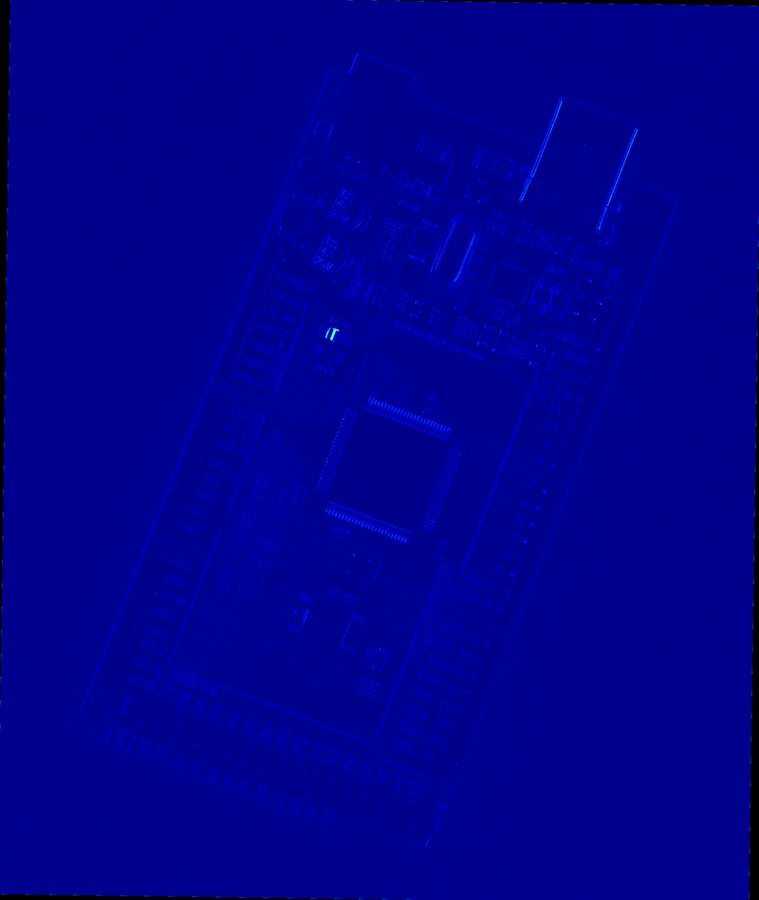

*Figure 4 — Saved difference heatmap for AECC4 against reference AECC1 (recorded output).*

---
# Overall conclusions and limitations

- **Q1:** Scale-normalized LoG with 3D extrema and colour validation identifies candidate flower heads. Validated candidate count alone is not flower-detection precision or recall.
- **Q2:** Custom two-point line RANSAC followed by three-point circle RANSAC recovers parameters close to ground truth on the supplied simulated dataset. Reversing the order changes ambiguous consensus assignments.
- **Q3:** Four corresponding image corners define a planar homography; a warped mask prevents the overlay background from corrupting unrelated pixels. The submitted visuals both use one architecture photo and would benefit from a second independent scene.
- **Q4:** SIFT + ratio-test BF matching + homography is effective where enough reliable visual correspondences exist. Large difference responses may originate in geometry, lighting or real hardware variation; direct defect attribution requires further validation.

**How to reproduce everything:** Supply the original photograph and PCB image dataset in the listed folders and select **Kernel → Restart & Run All**. This notebook contains all the required functions; the previously saved illustrations will still be visible independently. The notebook's generated `results/` directory stores fresh outputs when source inputs are present.